# B — Khảo sát tham số cơ sở: F0 → OFAT → ứng viên tổ hợp

Trong xử lý tín hiệu âm thanh, các bước tiền xử lý như lọc thông dải, pre-emphasis, phân tích FFT và trích xuất đặc trưng Mel thường được sử dụng nhằm chuẩn hóa tín hiệu và làm nổi bật những thông tin phổ có ích. Đặc biệt, pre-emphasis được ứng dụng trong một số quy trình trích xuất MFCC để điều chỉnh độ dốc phổ, làm nổi bật tương đối các thành phần tần số cao. Phương pháp này cũng xuất hiện trong nghiên cứu *Hybrid deep learning and YAMNet features for asthma diagnosis from respiratory sounds*.

Kế thừa cơ sở lý thuyết và các thí nghiệm ban đầu, nghiên cứu sử dụng **F0 làm cấu hình tham chiếu**, gồm `pre-emphasis=0,97**, **n_mels=64`, `n_fft=1024`, `hop_length=625` và bộ lọc Butterworth bậc 5. Trên kiến trúc tham chiếu **V1 – Separable CNN**, thí nghiệm OFAT (*One Factor At a Time*) được thực hiện với seed cố định **42**, lần lượt thay đổi từng tham số để xác định những yếu tố cần khảo sát sâu hơn.

Điểm quan trọng nhất là: **Mô hình hiện tại không trực tiếp nhận biết tình trạng viêm hay bệnh lý trong phổi. Nó nhận biết những thay đổi âm học do tình trạng đường thở tạo ra.**

**Trình tự khảo sát:** 9 cấu hình OFAT tại seed 42 → phân tích lỗi trên từng WAV → kiểm tra 4 cấu hình qua 3 seed → mở rộng sang 8 tổ hợp Front-End trong notebook C.

Seed 42 được sử dụng nhằm giữ nhất quán điều kiện huấn luyện ở giai đoạn thăm dò, không phải vì có chất lượng cao hơn các seed khác. Việc lựa chọn checkpoint seed 44 thuộc giai đoạn đánh giá tiếp theo.

Cơ sở lựa chọn V1 và lý do sử dụng F0 ban đầu đã được trình bày ở **A1.1**. Những đặc điểm về nguồn WAV, sample rate và giới hạn băng thông được phân tích độc lập trong **B0**.

## B0. Cấu hình F0 và phạm vi 9 thí nghiệm OFAT (seed 42)

| Tham số cơ sở | F0 | Vì sao thay đổi ở B? |
|---|---|---|
| Butterworth | Order 5, 100–2000 Hz | so bậc 3 và 7 |
| Pre-emphasis | 0,97 | so `0` và `0,95` |
| Mel filters | 64 | so 40 và 80 |
| FFT | 1024 | so 2048 |
| Hop length | 625 | so 800 |

**9 trial:** Gồm 9 trường hợp thử nghiệm khác nhau với bộ tham số như sau

| STT | Tên trial thử nghiệm | Hệ số Pre-emphasis | Order Butterworth | FFT | Hop length | Mel filter |
|---|---|---|---|---|---|---|
| 1 | F0 | 0.97 | 5 | 1024 | 625 | 64 | 
| 2 | order_3 | 0.97 | `3` | 1024 | 625 | 64 | 
| 3 | order_7 | 0.97 | `7` | 1024 | 625 | 64 | 
| 4 | pre_0 | `0` | 5 | 1024 | 625 | 64 | 
| 5 | pre_095 | `0.95` | 5 | 1024 | 625 | 64 | 
| 6 | mel_40 | 0.97 | 5 | 1024 | 625 | `40` | 
| 7 | mel_80 | 0.97 | 5 | 1024 | 625 | `80` | 
| 8 | hop_800 | 0.97 | 5 | 1024 | `800` | 64 | 
| 9 | fft_2048 | 0.97 | 5 | `2048` | 625 | 64 | 

OFAT đo **ảnh hưởng riêng** từng thay đổi trên F0, không tìm được tương tác Mel×FFT×pre và không đủ để chọn C4/s44. Cách đó được tiếp nối ở notebook C.

## B1. Thiết lập đường dẫn và truy vết thí nghiệm

Notebook này chỉ đọc checkpoint và bản ghi OFAT/paired-error hiện có trong `Frontend_Benchmarking`, không huấn luyện lại. 

Nguồn chuẩn là `results/val_summary.csv`, `training_metadata.json` và `val_predictions.csv` của từng trial. Nếu artifact thiếu hoặc sai provenance, notebook báo lỗi thay vì dùng số liệu ghi cứng. 

**OFAT ở seed 42**, kiểm tra nhiều seed được đánh giá **sau** OFAT. Không kết luận bệnh lý từ nguồn sample rate (tham khảo B0).

In [1]:
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

EXPECTED_RECIPE = 'V1_phase2_exact_float64_raw_float32_after_normalize_v2'
B1_SEED = 42
B1_VARIANTS = ('F0','order_3','order_7','pre_0','pre_095','mel_40','mel_80','hop_800','fft_2048')

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 60)

def find_benchmark_root():
    env_path = (os.environ.get('NCKH_FRONTEND_DIR') or
                os.environ.get('FRONTEND_BENCHMARK_ROOT'))
    if env_path:
        candidate = Path(env_path).expanduser().resolve()
        if (candidate / 'frontend_core.py').is_file():
            return candidate

    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        locations = (
            candidate,
            candidate / 'Frontend_Benchmarking',
            candidate / 'Experiments_Benchmarking' / 'Patient_Node' / 'Frontend_Benchmarking',
        )
        for location in locations:
            if (location / 'frontend_core.py').is_file():
                return location.resolve()
    return None

ROOT = find_benchmark_root()
if ROOT is None:
    print('CHƯA TÌM THẤY frontend_core.py. Mở notebook từ Frontend_Benchmarking hoặc thư mục con.')
    B0_DIR = None
    RESULTS_DIR = None
    ARTIFACTS_DIR = None
else:
    B0_DIR = ROOT / 'results' / 'B0_dataset_audit'
    RESULTS_DIR = ROOT / 'results'
    ARTIFACTS_DIR = ROOT / 'artifacts'
    print('Benchmark root:', ROOT)
    print('B0 audit:', B0_DIR)

def read_optional_csv(path):
    if path is None or not path.is_file():
        return pd.DataFrame()
    return pd.read_csv(path, encoding='utf-8-sig')

meta = read_optional_csv(B0_DIR / 'file_metadata.csv' if B0_DIR else None)
errors = read_optional_csv(B0_DIR / 'metadata_errors.csv' if B0_DIR else None)
manifest_path = B0_DIR / 'audit_manifest.json' if B0_DIR else None
manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path and manifest_path.is_file() else {}

# Tìm các prediction CSV theo thư mục dự án hoặc đường dẫn được chỉ định.
# Không ghi kết quả vào thư mục bất kỳ nếu chưa xác định ROOT.
# Neo CSV dự phòng tại root Frontend để notebook không phụ thuộc thư mục chạy hiện tại.
_default_pred_dir = ROOT if ROOT is not None else Path.cwd()
PRED_DIR = Path(os.environ.get('NCKH_VAL_PRED_DIR', str(_default_pred_dir))).expanduser().resolve()
def prediction_candidates(trial_id, alias):
    paths = []
    if ARTIFACTS_DIR is not None:
        paths.append(ARTIFACTS_DIR / 'models' / trial_id / 'val_predictions.csv')
    paths.extend([PRED_DIR / alias, PRED_DIR / 'results' / alias])
    if RESULTS_DIR is not None:
        paths.extend([RESULTS_DIR / alias, RESULTS_DIR / 'predictions' / alias])
    return list(dict.fromkeys(paths))

print('Đường dẫn CSV dự phòng:', PRED_DIR)

print('B chỉ phân tích OFAT/seed; B0 source audit nằm ở notebook riêng.')


Benchmark root: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking
B0 audit: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\B0_dataset_audit
Đường dẫn CSV dự phòng: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking
B chỉ phân tích OFAT/seed; B0 source audit nằm ở notebook riêng.


In [2]:
# B1.1 - OFAT SCOPE LOCK: đúng 9 cấu hình × seed 42, dù toàn dự án đã có B3/C.
from collections import defaultdict

CANDIDATE_CONFIG_COLS = [
    'low_cut_hz','high_cut_hz','filter_order','pre_emphasis',
    'n_mels','hop_length','n_fft'
]
# Không trộn experiment cũ, kể cả khi trial ID trùng tên.
EXCLUDED_TRIAL_IDS = set()
excluded_other_recipe = []
CFG_PATH = ROOT / 'configs' / 'candidates.csv' if ROOT else None
PLAN_PATH = RESULTS_DIR / 'experiment_plan.csv' if RESULTS_DIR else None
candidates = read_optional_csv(CFG_PATH)
plan_b1 = read_optional_csv(PLAN_PATH)
val_metrics = read_optional_csv(RESULTS_DIR / 'val_summary.csv' if RESULTS_DIR else None)
if not val_metrics.empty and 'trial_id' in val_metrics:
    val_metrics = val_metrics[
        ~val_metrics['trial_id'].astype(str).isin(EXCLUDED_TRIAL_IDS)
    ].copy()
trial_info = {}
if ARTIFACTS_DIR and (ARTIFACTS_DIR / 'models').is_dir():
    for path in sorted((ARTIFACTS_DIR / 'models').glob('*/training_metadata.json')):
        try:
            info = json.loads(path.read_text(encoding='utf-8'))
            info['trial_id'] = info.get('trial_id', path.parent.name)
            if info['trial_id'] in EXCLUDED_TRIAL_IDS:
                continue
            if str(info.get('architecture')) == 'V1':
                if info.get('training_recipe_id') == EXPECTED_RECIPE:
                    trial_info[info['trial_id']] = info
                else:
                    excluded_other_recipe.append((info['trial_id'],info.get('training_recipe_id')))
        except (ValueError, OSError) as exc:
            print('Không đọc được training metadata:',path,exc)

if not candidates.empty:
    candidates['variant_id'] = candidates['variant_id'].astype(str)
    candidates['enabled'] = candidates['enabled'].astype(str)
    base_rows = candidates[candidates['variant_id'].eq('F0')]
    if len(base_rows) == 1:
        f0_cfg = base_rows.iloc[0]
        changes = []
        for _,r in candidates.iterrows():
            diff = [k for k in CANDIDATE_CONFIG_COLS
                    if str(r[k]) != str(f0_cfg[k]) and
                    not (pd.to_numeric(r[k], errors='coerce') == pd.to_numeric(f0_cfg[k], errors='coerce'))]
            changes.append('BASELINE' if r['variant_id'] == 'F0' else
                           ', '.join(f'{k}: {f0_cfg[k]} → {r[k]}' for k in diff))
        candidates['difference_vs_F0'] = changes
    else:
        candidates['difference_vs_F0'] = 'F0 chưa xác thực'
    plan_map = (plan_b1.set_index('variant_id')['enabled'].astype(str).to_dict()
                if not plan_b1.empty and {'variant_id','enabled'} <= set(plan_b1) else {})
    infos_by_variant = defaultdict(list)
    for t,info in trial_info.items():
        if str(info.get('variant_id')) in B1_VARIANTS and int(info.get('seed',-1)) == B1_SEED:
            infos_by_variant[str(info['variant_id'])].append(t)
    if not val_metrics.empty and 'architecture' in val_metrics:
        val_metrics = val_metrics[val_metrics['architecture'].astype(str).eq('V1')].copy()
    evaluated = set(val_metrics['trial_id'].astype(str)) if 'trial_id' in val_metrics else set()
    # Lọc TRƯỚC KHI hiển thị: combo và các candidate ngoài B1 thuộc giai đoạn khác.
    inventory = candidates[candidates['variant_id'].isin(B1_VARIANTS)][
        ['variant_id','group','enabled','difference_vs_F0']].copy()
    inventory['stage_trial'] = inventory['variant_id'].map(lambda v: f'{v}__V1__s{B1_SEED}')
    inventory = inventory.set_index('variant_id').reindex(B1_VARIANTS).reset_index()
    inventory['enabled_in_plan'] = inventory['variant_id'].map(plan_map).fillna('no plan')
    inventory['trained_trials'] = inventory['variant_id'].map(
        lambda v: ', '.join(sorted(infos_by_variant.get(v,[]))) or '-')
    inventory['val_evaluated'] = inventory['variant_id'].map(
        lambda v: ', '.join(sorted(x for x in infos_by_variant.get(v,[]) if x in evaluated)) or '-')
    print('B1 - CHỈ 9 cấu hình OFAT, seed 42; enabled chỉ là cờ chạy, không thay đổi phạm vi báo cáo:')
    display(inventory)
    missing_configs = set(B1_VARIANTS) - set(candidates['variant_id'])
    if missing_configs:
        print('THIẾU cấu hình B1 trong candidates.csv:', sorted(missing_configs))
else:
    inventory = pd.DataFrame()
    print('Chưa thấy configs/candidates.csv; các cell tiếp theo vẫn có thể đọc model đã lưu.')
print('B1 scope:', len(B1_VARIANTS),'cấu hình × seed', B1_SEED, '| không hiển thị B3/C ở chương này.')
if excluded_other_recipe:
    print('Có metadata khác recipe; không dùng để so sánh ở B1 (số trial):',len(excluded_other_recipe))


B1 - CHỈ 9 cấu hình OFAT, seed 42; enabled chỉ là cờ chạy, không thay đổi phạm vi báo cáo:


,variant_id,group,enabled,difference_vs_F0,stage_trial,enabled_in_plan,trained_trials,val_evaluated
0,F0,baseline,1,BASELINE,F0__V1__s42,1,F0__V1__s42,F0__V1__s42
1,order_3,filter_order,0,filter_order: 5 → 3,order_3__V1__s42,0,order_3__V1__s42,order_3__V1__s42
2,order_7,filter_order,0,filter_order: 5 → 7,order_7__V1__s42,0,order_7__V1__s42,order_7__V1__s42
3,pre_0,pre_emphasis,0,pre_emphasis: 0.97 → 0.0,pre_0__V1__s42,0,pre_0__V1__s42,pre_0__V1__s42
4,pre_095,pre_emphasis,0,pre_emphasis: 0.97 → 0.95,pre_095__V1__s42,0,pre_095__V1__s42,pre_095__V1__s42
5,mel_40,n_mels,0,n_mels: 64 → 40,mel_40__V1__s42,0,mel_40__V1__s42,mel_40__V1__s42
6,mel_80,n_mels,0,n_mels: 64 → 80,mel_80__V1__s42,0,mel_80__V1__s42,mel_80__V1__s42
7,hop_800,hop_length,0,hop_length: 625 → 800,hop_800__V1__s42,0,hop_800__V1__s42,hop_800__V1__s42
8,fft_2048,n_fft,0,n_fft: 1024 → 2048,fft_2048__V1__s42,0,fft_2048__V1__s42,fft_2048__V1__s42


B1 scope: 9 cấu hình × seed 42 | không hiển thị B3/C ở chương này.


### B1.1 Bảng thông số các cấu hình trial khi đi qua **VALIDATION**

Đối chiếu trực tiếp `results/val_summary.csv` với `training_metadata.json`, fingerprint Train/Val và cấu hình OFAT. Notebook dùng artifact chính trong dự án để liệt kê các chỉ số của các cấu hình trial. 

Trường hợp ếu thiếu hoặc sai provenance thì dừng và báo lỗi, không thay bằng snapshot ghi cứng.


In [3]:
# B1.2 - So khớp metadata và CSV. Giữ cả trial đã train khi enabled về 0.
NUMERIC_METRICS = ['seed','asthma_recall','non_asthma_recall','asthma_fn',
                   'non_asthma_fp','accuracy','balanced_accuracy','macro_f1',
                   'log_loss','parameter_count','train_seconds']
if not val_metrics.empty:
    val_metrics = val_metrics.copy()
    if 'architecture' in val_metrics:
        val_metrics = val_metrics[val_metrics['architecture'].astype(str).eq('V1')].copy()
    for col in NUMERIC_METRICS:
        if col in val_metrics:
            val_metrics[col] = pd.to_numeric(val_metrics[col], errors='coerce')
    if 'trial_id' in val_metrics:
        val_metrics['trial_id'] = val_metrics['trial_id'].astype(str)

comparison = val_metrics.copy() if not val_metrics.empty else pd.DataFrame()
b1_comparison = pd.DataFrame()
if comparison.empty:
    print('CHỜ VALIDATION: chưa có results/val_summary.csv. B1.1 vẫn cho biết trạng thái candidate.')
else:
    status = []
    for _,row in comparison.iterrows():
        info = trial_info.get(row['trial_id'])
        flags = []
        if info is None:
            flags.append('NO_MATCHING_RECIPE_METADATA')
        else:
            if info.get('training_recipe_id') != EXPECTED_RECIPE:
                flags.append('WRONG_TRAINING_RECIPE')
            for field in ('config_sha256','variant_id','architecture','seed'):
                if str(row.get(field)) != str(info.get(field)):
                    flags.append('MISMATCH_'+field)
            if manifest:
                for field in ('train_fingerprint','val_fingerprint'):
                    if info.get(field) != manifest.get(field):
                        flags.append('DATASET_'+field)
        status.append('OK' if not flags else ', '.join(flags))
    comparison['provenance'] = status
    comparison['best_epoch'] = comparison['trial_id'].map(
        lambda t: trial_info.get(t,{}).get('best_epoch',np.nan))
    comparison['input_shape'] = comparison['trial_id'].map(
        lambda t: str(trial_info.get(t,{}).get('input_shape','?')))
    comparison['builder_sha256'] = comparison['trial_id'].map(
        lambda t: trial_info.get(t,{}).get('builder_sha256'))
    # B1_VIEW khóa cứng stage; 'comparison' đầy đủ chỉ dành cho B3 ở dưới.
    view = ['trial_id','variant_id','seed','provenance','asthma_recall',
            'asthma_fn','macro_f1','balanced_accuracy','accuracy',
            'parameter_count','input_shape','best_epoch','train_seconds']
    b1_comparison = comparison[
        comparison['variant_id'].isin(B1_VARIANTS) & comparison['seed'].eq(B1_SEED)
    ].copy()
    print(f'B1 - {len(b1_comparison)}/9 OFAT trials × seed {B1_SEED}; không hiển thị các seed khác/combo:')
    b1_provenance_view = b1_comparison[[c for c in view if c in b1_comparison]].copy()
    b1_provenance_view = b1_provenance_view.sort_values(
        ['accuracy', 'macro_f1'], ascending=[False, False], na_position='last'
    )
    display(b1_provenance_view.round(4))
    if (b1_comparison['provenance'] != 'OK').any():
        print('CẢNH BÁO: Trial lỗi provenance không được dùng để kết luận hơn-kém.')

# Chỉ so theo F0 của đúng seed và recipe; kết quả lịch sử chỉ có log Test không tự thành baseline.
def comparable_to_f0(row, base_row):
    x, b = trial_info.get(str(row['trial_id'])),trial_info.get(str(base_row['trial_id']))
    if not x or not b or row.get('provenance')!='OK' or base_row.get('provenance')!='OK':
        return False, 'Thiếu metadata hoặc provenance không hợp lệ'
    checks = ('architecture','builder_sha256','training_recipe_id','seed','train_fingerprint',
              'val_fingerprint','epochs_requested','batch_size')
    bad = [k for k in checks if x.get(k)!=b.get(k)]
    return (not bad), ('OK' if not bad else 'Khác: '+', '.join(bad))

f0_by_seed = {}
if not comparison.empty:
    for seed,sub in comparison[comparison['variant_id'].eq('F0')].groupby('seed'):
        if len(sub)==1 and sub.iloc[0]['provenance']=='OK':
            f0_by_seed[int(seed)] = sub.iloc[0]
    print('Đối chứng B1: F0 seed 42 hợp lệ:',B1_SEED in f0_by_seed)
    print("Đối chứng trên tập VAL, được sắp xếp theo Accuracy giảm dần !")
    if not f0_by_seed:
        print('THIẾU ĐỐI CHỨNG F0: chưa tính delta/improvement; log Test cũ không thay được Validation.')


B1 - 9/9 OFAT trials × seed 42; không hiển thị các seed khác/combo:


,trial_id,variant_id,seed,provenance,asthma_recall,asthma_fn,macro_f1,balanced_accuracy,accuracy,parameter_count,input_shape,best_epoch,train_seconds
12,mel_40__V1__s42,mel_40,42,OK,1.0000,0,0.9745,0.9871,0.9805,331386,"[40, 129, 1]",17.0,208.1415
15,fft_2048__V1__s42,fft_2048,42,OK,0.9474,2,0.9567,0.9608,0.9675,527994,"[64, 129, 1]",17.0,274.6189
9,pre_0__V1__s42,pre_0,42,OK,1.0000,0,0.9501,0.9741,0.9610,527994,"[64, 129, 1]",26.0,543.2982
1,order_3__V1__s42,order_3,42,OK,0.9737,1,0.9335,0.9567,0.9481,527994,"[64, 129, 1]",15.0,230.6340
4,mel_80__V1__s42,mel_80,42,OK,0.9211,3,0.9313,0.9390,0.9481,659066,"[80, 129, 1]",15.0,221.7022
3,pre_095__V1__s42,pre_095,42,OK,1.0000,0,0.9269,0.9612,0.9416,527994,"[64, 129, 1]",16.0,380.8560
6,F0__V1__s42,F0,42,OK,0.9737,1,0.9258,0.9524,0.9416,527994,"[64, 129, 1]",13.0,246.8990
2,order_7__V1__s42,order_7,42,OK,0.9474,2,0.9246,0.9435,0.9416,527994,"[64, 129, 1]",17.0,354.2818
5,hop_800__V1__s42,hop_800,42,OK,0.9474,2,0.9246,0.9435,0.9416,396922,"[64, 101, 1]",15.0,356.1939


Đối chứng B1: F0 seed 42 hợp lệ: True
Đối chứng trên tập VAL, được sắp xếp theo Accuracy giảm dần !


### B1.2 Bảng và biểu đồ 9 trial (Validation)
Đo Accuracy, Macro-F1, Balanced Accuracy, Asthma FN, số tham số và chênh lệch với F0. 

Các chỉ số được truy trực tiếp từ `results/val_summary.csv`, rồi kiểm tra lại confusion matrix trên 9 file `artifacts/models/<trial_id>/val_predictions.csv`.


B1 VERIFIED: 9/9 trial lấy trực tiếp từ val_summary + metadata + predictions.
Được sắp xếp giảm dần theo ACCURACY.


,variant_id,accuracy,delta_accuracy_pp,macro_f1,balanced_accuracy,asthma_recall,asthma_fn,non_asthma_fp,log_loss,parameter_count,param_reduction_pct
0,mel_40,0.98052,3.89610,0.97446,0.98707,1.00000,0,3,0.05372,331386,37.23679
1,fft_2048,0.96753,2.59740,0.95671,0.96075,0.94737,2,3,0.09408,527994,0.00000
2,pre_0,0.96104,1.94805,0.95014,0.97414,1.00000,0,6,0.10022,527994,0.00000
3,order_3,0.94805,0.64935,0.93352,0.95667,0.97368,1,7,0.17478,527994,0.00000
4,mel_80,0.94805,0.64935,0.93133,0.93897,0.92105,3,5,0.14302,659066,-24.82452
5,pre_095,0.94156,0.00000,0.92688,0.96121,1.00000,0,9,0.14416,527994,0.00000
6,F0,0.94156,0.00000,0.92578,0.95236,0.97368,1,8,0.18244,527994,0.00000
7,order_7,0.94156,0.00000,0.92462,0.94351,0.94737,2,7,0.19851,527994,0.00000
8,hop_800,0.94156,0.00000,0.92462,0.94351,0.94737,2,7,0.24962,396922,24.82452


,trial_id,val_summary,metadata,predictions,status
0,F0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
1,order_3__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
2,order_7__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
3,pre_0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
4,pre_095__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
5,mel_40__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
6,mel_80__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
7,hop_800__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED
8,fft_2048__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,VERIFIED


Mỗi 1 mẫu Validation tương đương: 0.649 điểm phần trăm Accuracy.


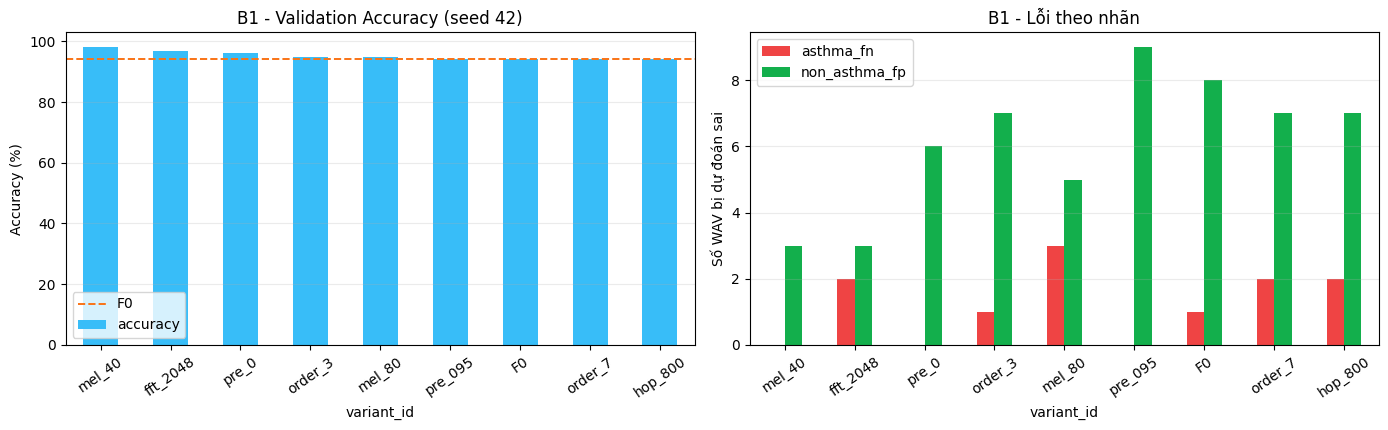

In [4]:
# B1.3 - Truy trực tiếp 9 trial OFAT từ nguồn dữ liệu chính.
# Nguồn chỉ số: results/val_summary.csv. Nguồn kiểm chứng từng WAV:
# artifacts/models/<trial_id>/val_predictions.csv.
b1_records = []
b1_trace_rows = []
for variant in B1_VARIANTS:
    trial_id = f'{variant}__V1__s{B1_SEED}'
    rows = b1_comparison[b1_comparison['trial_id'].eq(trial_id)]
    if len(rows) != 1:
        raise ValueError(
            f'{trial_id}: cần đúng 1 hàng trong results/val_summary.csv, hiện có {len(rows)}'
        )
    row = rows.iloc[0]
    if row['provenance'] != 'OK':
        raise ValueError(f"{trial_id}: provenance không hợp lệ: {row['provenance']}")

    pred_path = ARTIFACTS_DIR / 'models' / trial_id / 'val_predictions.csv'
    if not pred_path.is_file():
        raise FileNotFoundError(
            f'{trial_id}: thiếu nguồn chính {pred_path}; không dùng file dự phòng.'
        )

    pred = pd.read_csv(pred_path, encoding='utf-8-sig')
    required = {'file', 'true_label', 'predicted_label', 'p_non_asthma'}
    missing = required - set(pred.columns)
    if missing:
        raise ValueError(f'{pred_path}: thiếu cột {sorted(missing)}')
    pred = pred[['file', 'true_label', 'predicted_label', 'p_non_asthma']].copy()
    pred['file'] = pred['file'].astype(str).str.replace(chr(92), '/', regex=False)
    if pred['file'].duplicated().any():
        raise ValueError(f'{pred_path}: có tên WAV trùng')
    for col in ('true_label', 'predicted_label'):
        pred[col] = pd.to_numeric(pred[col], errors='raise').astype(int)
    pred['p_non_asthma'] = pd.to_numeric(pred['p_non_asthma'], errors='raise')

    if len(pred) != 154:
        raise ValueError(f'{pred_path}: cần 154 WAV, hiện có {len(pred)}')
    if not pred['true_label'].isin([0, 1]).all() or not pred['predicted_label'].isin([0, 1]).all():
        raise ValueError(f'{pred_path}: nhãn phải thuộc 0/1')
    if not pred['p_non_asthma'].between(0, 1).all():
        raise ValueError(f'{pred_path}: p_non_asthma ngoài [0, 1]')
    threshold_pred = pred['p_non_asthma'].ge(0.5).astype(int)
    if not pred['predicted_label'].eq(threshold_pred).all():
        raise ValueError(f'{pred_path}: predicted_label không khớp threshold 0.5')

    asthma_ok = int(((pred['true_label'] == 0) & (pred['predicted_label'] == 0)).sum())
    asthma_fn = int(((pred['true_label'] == 0) & (pred['predicted_label'] == 1)).sum())
    non_asthma_fp = int(((pred['true_label'] == 1) & (pred['predicted_label'] == 0)).sum())
    non_asthma_ok = int(((pred['true_label'] == 1) & (pred['predicted_label'] == 1)).sum())
    cm = [asthma_ok, asthma_fn, non_asthma_fp, non_asthma_ok]
    accuracy_from_predictions = (asthma_ok + non_asthma_ok) / len(pred)

    if asthma_fn != int(row['asthma_fn']) or non_asthma_fp != int(row['non_asthma_fp']):
        raise ValueError(f'{trial_id}: confusion matrix khác val_summary.csv')
    if not np.isclose(accuracy_from_predictions, float(row['accuracy']), atol=1e-12):
        raise ValueError(f'{trial_id}: accuracy khác val_summary.csv')

    b1_records.append({
        'trial_id': trial_id,
        'variant_id': variant,
        'seed': int(row['seed']),
        'accuracy': float(row['accuracy']),
        'balanced_accuracy': float(row['balanced_accuracy']),
        'macro_f1': float(row['macro_f1']),
        'asthma_recall': float(row['asthma_recall']),
        'non_asthma_recall': float(row['non_asthma_recall']),
        'asthma_fn': asthma_fn,
        'non_asthma_fp': non_asthma_fp,
        'log_loss': float(row['log_loss']),
        'parameter_count': int(row['parameter_count']),
        'cm': cm,
        'n_correct': asthma_ok + non_asthma_ok,
        'n_total': len(pred),
    })
    b1_trace_rows.append({
        'trial_id': trial_id,
        'val_summary': str(RESULTS_DIR / 'val_summary.csv'),
        'metadata': str(ARTIFACTS_DIR / 'models' / trial_id / 'training_metadata.json'),
        'predictions': str(pred_path),
        'status': 'VERIFIED',
    })

b1_report = pd.DataFrame(b1_records)
b1_trace = pd.DataFrame(b1_trace_rows)
assert len(b1_report) == 9 and b1_report['variant_id'].nunique() == 9
assert b1_report['n_total'].eq(154).all() and b1_report['seed'].eq(B1_SEED).all()

base = b1_report.set_index('variant_id').loc['F0']
b1_report['delta_accuracy_pp'] = (b1_report['accuracy'] - base['accuracy']) * 100
b1_report['delta_macro_f1_pp'] = (b1_report['macro_f1'] - base['macro_f1']) * 100
b1_report['param_reduction_pct'] = (
    1 - b1_report['parameter_count'] / base['parameter_count']
) * 100
ranking = b1_report.sort_values(
    ['accuracy', 'macro_f1'], ascending=[False, False]
).reset_index(drop=True)

view = [
    'variant_id', 'accuracy', 'delta_accuracy_pp', 'macro_f1',
    'balanced_accuracy', 'asthma_recall', 'asthma_fn', 'non_asthma_fp',
    'log_loss', 'parameter_count', 'param_reduction_pct',
]
print('B1 VERIFIED: 9/9 trial lấy trực tiếp từ val_summary + metadata + predictions.')
print('Được sắp xếp giảm dần theo ACCURACY.')
display(ranking[view].round(5))
display(b1_trace)
print('Mỗi 1 mẫu Validation tương đương:', round(100 / 154, 3),
      'điểm phần trăm Accuracy.')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
view_plot = ranking.set_index('variant_id')
view_plot['accuracy'].mul(100).plot.bar(ax=axes[0], rot=35, color='#38bdf8')
axes[0].axhline(
    base['accuracy'] * 100, linestyle='--', linewidth=1.4,
    color='#f97316', label='F0'
)
axes[0].set(title='B1 - Validation Accuracy (seed 42)', ylabel='Accuracy (%)')
axes[0].legend()
axes[0].grid(axis='y', alpha=.25)
view_plot[['asthma_fn', 'non_asthma_fp']].plot.bar(
    ax=axes[1], rot=35, color=['#ef4444', "#13AF4C"]
)
axes[1].set(title='B1 - Lỗi theo nhãn', ylabel='Số WAV bị dự đoán sai')
axes[1].grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

**Kết quả B1:** Các xếp hạng OFAT tại **seed 42** chỉ có tính thăm dò. Một cấu hình có Validation Accuracy cao hơn F0 ở s42 chưa thể được coi là tốt nhất qua seed khác hoặc sau lượng tử hóa. 

Đặc biệt, `mel_40`, `pre_0` và `fft_2048` là các hướng ứng viên cho phép thử tổ hợp tiếp theo.

---

## B2 — Paired-error audit: **Validation 154 WAV, seed 42**

Kiểm toán lỗi theo cặp

Cùng file, cùng nhãn và cùng seed, so F0 với `pre_0`, `mel_40`, `fft_2048`. B2 không train, chỉ so WAV nào F0 sai nhưng candidate đúng, và WAV nào candidate gây lỗi mới. **Không dùng Test**.


In [5]:
# B2.1 - Nạp predictions trực tiếp; ưu tiên artifact trên máy, dự phòng bốn CSV được xuất thủ công.
B2_VARIANTS = ('F0', 'pre_0', 'mel_40', 'fft_2048')
B2_FILE_ALIASES = {
    'F0': 'val_predictions_F0.csv',
    'pre_0': 'val_predictions_pre0.csv',
    'mel_40': 'val_predictions_mel40.csv',
    'fft_2048': 'val_predictions2048.csv',
}
B2_CSV_DIR = PRED_DIR  # Đặt biến môi trường NCKH_VAL_PRED_DIR nếu CSV ngoài repo.
b2_preds = {}
b2_paths = {}
b2_errors = []

for variant in B2_VARIANTS:
    tid = f'{variant}__V1__s42'
    choices = prediction_candidates(tid, B2_FILE_ALIASES[variant])
    found = next((p for p in choices if p.is_file()), None)
    if found is None:
        b2_errors.append(f'{variant}: chưa tìm thấy val_predictions.csv')
        continue
    try:
        d = pd.read_csv(found, encoding='utf-8-sig')
        required = {'file', 'true_label', 'predicted_label', 'p_non_asthma'}
        if not required.issubset(d.columns):
            raise ValueError('Thiếu cột: ' + str(required - set(d.columns)))
        d = d[['file', 'true_label', 'predicted_label', 'p_non_asthma']].copy()
        d['file'] = d['file'].astype(str).str.replace('\\', '/', regex=False)
        for col in ['true_label','predicted_label']:
            d[col] = pd.to_numeric(d[col], errors='raise').astype(int)
        d['p_non_asthma'] = pd.to_numeric(d['p_non_asthma'], errors='raise')
        if (d['file'].duplicated().any() or
                not d['true_label'].isin([0,1]).all() or
                not d['predicted_label'].isin([0,1]).all() or
                not d['p_non_asthma'].between(0,1).all() or
                not (d['predicted_label'] == (d['p_non_asthma'] >= .5).astype(int)).all()):
            raise ValueError('Filename trùng, nhãn sai, xác suất ngoài [0,1] hoặc ngưỡng 0.5 không khớp')
        d = d.set_index('file').sort_index()
        if len(d) != 154 or int(d['true_label'].eq(0).sum()) != 38 or int(d['true_label'].eq(1).sum()) != 116:
            raise ValueError('Validation coverage khác 154 = 38 Asthma + 116 Non-Asthma')
        b2_preds[variant], b2_paths[variant] = d, str(found)
    except (ValueError, OSError, KeyError) as exc:
        b2_errors.append(f'{variant}: {exc}')

if len(b2_preds) == len(B2_VARIANTS):
    base = b2_preds['F0']
    for variant, d in b2_preds.items():
        if not base.index.equals(d.index) or not base['true_label'].equals(d['true_label']):
            b2_errors.append(f'{variant}: WAV/nhãn không khớp F0')
    if b2_errors:
        b2_preds = {}
if b2_errors:
    print('CHƯA ĐỦ DỮ LIỆU B2:', *b2_errors, sep='\n- ')
else:
    print('B2 VERIFIED: 4 × 154 WAV cùng tên, cùng nhãn, cùng ngưỡng 0.5; seed 42.')
    display(pd.DataFrame([{'Trial': f'{v}__V1__s42', 'Nguồn CSV': b2_paths[v]} for v in B2_VARIANTS]))


B2 VERIFIED: 4 × 154 WAV cùng tên, cùng nhãn, cùng ngưỡng 0.5; seed 42.


,Trial,Nguồn CSV
0,F0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...
1,pre_0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...
2,mel_40__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...
3,fft_2048__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...


,candidate,n,accuracy_%,fixed_F0,new_errors,both_wrong,asthma_missed,non_asthma_misclassified
0,F0,154,94.16,0,0,9,1,8
1,pre_0,154,96.10,5,2,4,0,6
2,mel_40,154,98.05,6,0,3,0,3
3,fft_2048,154,96.75,5,1,4,2,3


Những WAV có thay đổi trạng thái đúng/sai - không in toàn bộ 154 WAV:


,candidate,file,label,change,p_non_F0,p_non_candidate
0,fft_2048,Asthma/val/AST_036__P6AsthmaIU_26__take02.wav,Asthma,Lỗi mới,0.49898,0.70024
1,fft_2048,Non_Asthma_Disease/val/P19Pneumonia33O.wav,Non-Asthma,Sửa lỗi F0,0.10552,0.64356
2,fft_2048,Non_Asthma_Disease/val/P19Pneumonia41U.wav,Non-Asthma,Sửa lỗi F0,0.40539,0.73514
3,fft_2048,Non_Asthma_Disease/val/P19Pneumonia90X.wav,Non-Asthma,Sửa lỗi F0,0.06182,0.96742
4,fft_2048,Non_Asthma_Disease/val/P33COPDMc_258.wav,Non-Asthma,Sửa lỗi F0,0.05577,0.50966
5,fft_2048,Non_Asthma_Disease/val/P35COPDMc_280.wav,Non-Asthma,Sửa lỗi F0,0.09803,0.90745
6,mel_40,Asthma/val/AST_036__P6AsthmaIU_26__take01.wav,Asthma,Sửa lỗi F0,0.78813,0.14917
7,mel_40,Non_Asthma_Disease/val/COPD_009__P33COPDPr_257...,Non-Asthma,Sửa lỗi F0,0.00332,0.77734
8,mel_40,Non_Asthma_Disease/val/COPD_009__P33COPDPr_257...,Non-Asthma,Sửa lỗi F0,0.21746,0.96811
9,mel_40,Non_Asthma_Disease/val/P19Pneumonia41U.wav,Non-Asthma,Sửa lỗi F0,0.40539,0.92288


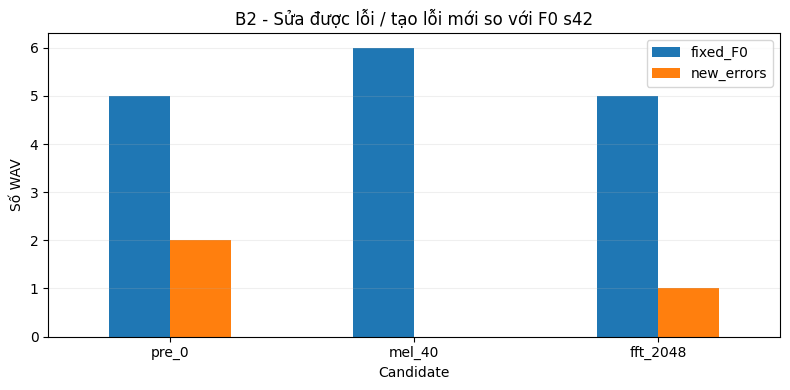

In [6]:
# B2.2 - Paired error audit: số mẫu candidate sửa được vs số mẫu mới làm sai.
b2_summary = pd.DataFrame()
b2_changes = pd.DataFrame()
if not b2_preds:
    print('CHỜ B2: nạp đủ 4 CSV theo hướng dẫn B2.1.')
else:
    base = b2_preds['F0']
    bc = base['true_label'].eq(base['predicted_label'])
    summary, changes = [], []
    for variant in B2_VARIANTS:
        d = b2_preds[variant]
        cc = d['true_label'].eq(d['predicted_label'])
        summary.append({
            'candidate': variant, 'n': len(d),
            'accuracy_%': 100 * float(cc.mean()),
            'fixed_F0': int((~bc & cc).sum()),
            'new_errors': int((bc & ~cc).sum()),
            'both_wrong': int((~bc & ~cc).sum()),
            'asthma_missed': int((d['true_label'].eq(0) & ~cc).sum()),
            'non_asthma_misclassified': int((d['true_label'].eq(1) & ~cc).sum()),
        })
        for label, label_name in ((0, 'Asthma'), (1, 'Non-Asthma')):
            mask = base['true_label'].eq(label)
            for f in base.index[mask & (bc != cc)]:
                changes.append({
                    'candidate': variant, 'file': f, 'label': label_name,
                    'change': 'Sửa lỗi F0' if bool(cc[f]) else 'Lỗi mới',
                    'p_non_F0': float(base.at[f, 'p_non_asthma']),
                    'p_non_candidate': float(d.at[f, 'p_non_asthma']),
                })
    b2_summary = pd.DataFrame(summary)
    b2_changes = pd.DataFrame(changes)
    display(b2_summary.round(2))
    if not b2_changes.empty:
        print('Những WAV có thay đổi trạng thái đúng/sai - không in toàn bộ 154 WAV:')
        display(b2_changes.sort_values(['candidate','label','change']).reset_index(drop=True).round(5))
    ax = b2_summary[b2_summary['candidate'].ne('F0')].set_index('candidate')[
        ['fixed_F0','new_errors']].plot.bar(figsize=(8,4), rot=0)
    ax.set(title='B2 - Sửa được lỗi / tạo lỗi mới so với F0 s42', xlabel='Candidate', ylabel='Số WAV')
    ax.grid(axis='y',alpha=.2)
    plt.tight_layout(); plt.show()


**Kết luận B2:** Trên cùng 154 WAV ở seed 42:
- `mel_40` sửa **6** lỗi của F0 và tạo **0** lỗi mới
- `pre_0` sửa **5** và tạo **2**
- `fft_2048` sửa **5** và tạo **1** lỗi mới (liên quan Asthma). 

Đây là kết quả cặp trên Validation, không chứng minh khả năng tổng quát hóa độc lập. Cả ba tiếp tục đáng khảo sát ở B3.

---

## B3 — Độ nhạy theo seed: **4 cấu hình × 3 seed** (Validation)

Sử dụng F0, `pre_0`, `mel_40`, `fft_2048` tại **42, 43, 44**, tổng **12 trial trên cùng 154 WAV Validation**. Giữ nguyên recipe Phase 2, chỉ đánh giá độ biến thiên giữa các lần khởi tạo. Mọi số liệu được lấy trực tiếp từ `val_summary.csv`, metadata và prediction CSV của từng trial.


In [7]:
# B3.1 - Truy trực tiếp 12 trial từ val_summary.csv và training_metadata.json.
B3_VARIANTS = ('F0', 'pre_0', 'mel_40', 'fft_2048')
B3_SEEDS = (42, 43, 44)
B3_COMMON_META_KEYS = (
    'architecture', 'builder_sha256', 'training_recipe_id',
    'train_fingerprint', 'val_fingerprint', 'epochs_requested',
    'batch_size', 'op_determinism_enabled',
)

b3_rows = []
b3_audit_rows = []
b3_profiles = []
for variant in B3_VARIANTS:
    for seed in B3_SEEDS:
        trial_id = f'{variant}__V1__s{seed}'
        rows = comparison[comparison['trial_id'].eq(trial_id)]
        info = trial_info.get(trial_id)
        reasons = []

        if len(rows) != 1:
            reasons.append(f'VAL_SUMMARY_COUNT={len(rows)}')
            row = None
        else:
            row = rows.iloc[0]
            if row['provenance'] != 'OK':
                reasons.append('VAL_PROVENANCE:' + str(row['provenance']))

        if info is None:
            reasons.append('MISSING_METADATA')
        else:
            if info.get('training_recipe_id') != EXPECTED_RECIPE:
                reasons.append('WRONG_RECIPE')
            missing = [key for key in B3_COMMON_META_KEYS if info.get(key) is None]
            if missing:
                reasons.append('MISSING_FIELDS:' + ','.join(missing))
            if manifest:
                for key in ('train_fingerprint', 'val_fingerprint'):
                    if info.get(key) != manifest.get(key):
                        reasons.append('DIFFERENT_' + key)
            if not missing and info.get('training_recipe_id') == EXPECTED_RECIPE:
                b3_profiles.append(
                    (trial_id, tuple(str(info[key]) for key in B3_COMMON_META_KEYS))
                )

        if row is not None:
            b3_rows.append({
                'variant': variant,
                'seed': int(row['seed']),
                'accuracy': float(row['accuracy']),
                'macro_f1': float(row['macro_f1']),
                'balanced_accuracy': float(row['balanced_accuracy']),
                'asthma_recall': float(row['asthma_recall']),
                'non_asthma_recall': float(row['non_asthma_recall']),
                'asthma_fn': int(row['asthma_fn']),
                'non_asthma_fp': int(row['non_asthma_fp']),
                'log_loss': float(row['log_loss']),
                'params': int(row['parameter_count']),
                'trial_id': trial_id,
            })

        b3_audit_rows.append({
            'trial_id': trial_id,
            'variant': variant,
            'seed': seed,
            'status': 'OK' if not reasons else '; '.join(reasons),
        })

b3_report = pd.DataFrame(b3_rows)
b3_inventory = pd.DataFrame(b3_audit_rows)
if b3_profiles and len({profile for _, profile in b3_profiles}) > 1:
    b3_inventory['status'] = b3_inventory['status'].apply(
        lambda value: ('PROTOCOL_DRIFT; ' + value)
        if value != 'OK' else 'PROTOCOL_DRIFT'
    )

b3_provenance_ok = bool(
    len(b3_report) == len(B3_VARIANTS) * len(B3_SEEDS)
    and len(b3_inventory) == len(B3_VARIANTS) * len(B3_SEEDS)
    and b3_inventory['status'].eq('OK').all()
    and not b3_report[['variant', 'seed']].duplicated().any()
)
if not b3_provenance_ok:
    display(b3_inventory.pivot(index='seed', columns='variant', values='status'))
    raise ValueError(
        'B3 chưa đủ 12 trial hợp lệ từ val_summary.csv + metadata; '
        'không dùng snapshot thay thế.'
    )

print('B3 VERIFIED: 12/12 trial lấy trực tiếp từ val_summary.csv + metadata.')
display(
    b3_report[
        ['variant', 'seed', 'accuracy', 'macro_f1', 'asthma_fn', 'non_asthma_fp']
    ].sort_values(['variant', 'seed']).round(5)
)
display(b3_inventory.pivot(index='seed', columns='variant', values='status'))

B3 VERIFIED: 12/12 trial lấy trực tiếp từ val_summary.csv + metadata.


,variant,seed,accuracy,macro_f1,asthma_fn,non_asthma_fp
0,F0,42,0.94156,0.92578,1,8
1,F0,43,0.97403,0.96566,1,3
2,F0,44,1.00000,1.00000,0,0
9,fft_2048,42,0.96753,0.95671,2,3
10,fft_2048,43,0.96753,0.95812,0,5
11,fft_2048,44,0.97403,0.96623,0,4
6,mel_40,42,0.98052,0.97446,0,3
7,mel_40,43,0.96104,0.95014,0,6
8,mel_40,44,0.95455,0.94041,2,5
3,pre_0,42,0.96104,0.95014,0,6


variant,F0,fft_2048,mel_40,pre_0
seed,,,,
42,OK,OK,OK,OK
43,OK,OK,OK,OK
44,OK,OK,OK,OK


### B3.1 Bảng từng seed, Mean ± sample SD và biểu đồ
**Tất cả chỉ số là Validation**, không phải Test. SD của 3 seed chỉ là thống kê mô tả, không thể xem như khoảng tin cậy tổng quát.


B3: Mean ± sample SD, trên 3 seed (chưa được xem là độc lập theo WAV):


,variant,n_seeds,accuracy_mean,accuracy_sd,accuracy_min,accuracy_max,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,asthma_recall_mean,asthma_fn_sum,non_asthma_fp_sum,log_loss_mean,log_loss_sd,params
0,F0,3,0.97186,0.02928,0.94156,1.00000,0.96382,0.03714,0.97542,0.98246,2,11,0.09916,0.08919,527994
1,pre_0,3,0.97186,0.01875,0.96104,0.99351,0.96333,0.02428,0.97542,0.98246,2,11,0.05987,0.04354,527994
2,fft_2048,3,0.96970,0.00375,0.96753,0.97403,0.96035,0.00514,0.97399,0.98246,2,12,0.07413,0.01811,527994
3,mel_40,3,0.96537,0.01352,0.95455,0.98052,0.95501,0.01754,0.97111,0.98246,2,14,0.08573,0.02772,331386


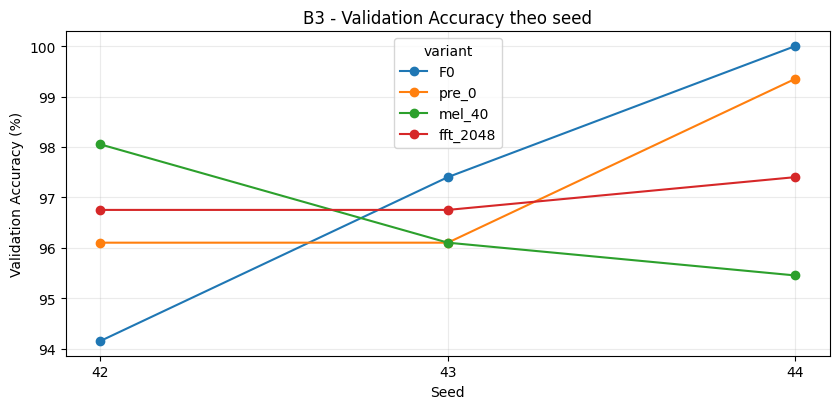

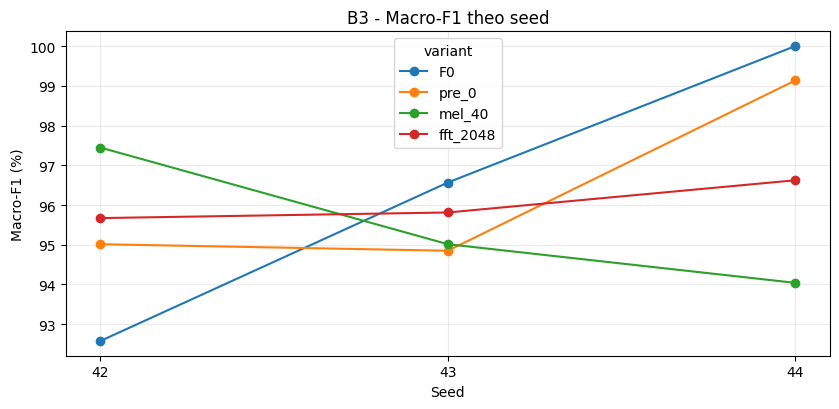

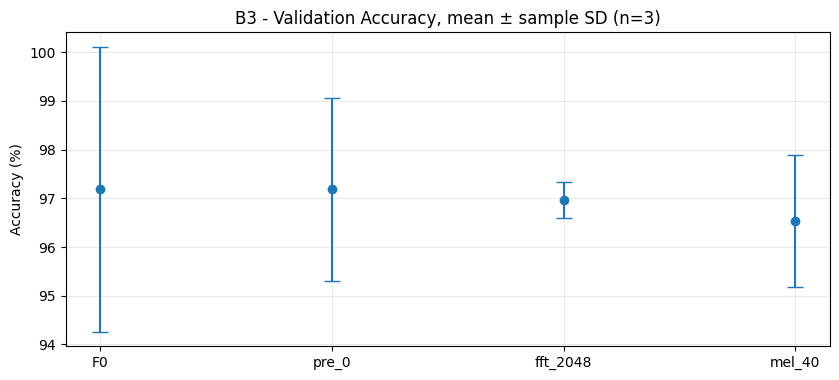

In [8]:
# B3.2 - Dùng 12 trial truy trực tiếp từ nguồn Validation; không dùng Test.
b3_all = b3_report.copy()
b3_complete = (len(b3_all) == len(B3_VARIANTS)*len(B3_SEEDS))
metrics = ['accuracy', 'macro_f1', 'balanced_accuracy', 'asthma_recall',
           'asthma_fn', 'non_asthma_fp', 'log_loss', 'params']
b3_summary = b3_all.groupby('variant').agg(
    n_seeds=('seed','nunique'),
    accuracy_mean=('accuracy','mean'), accuracy_sd=('accuracy','std'),
    accuracy_min=('accuracy','min'), accuracy_max=('accuracy','max'),
    macro_f1_mean=('macro_f1','mean'), macro_f1_sd=('macro_f1','std'),
    balanced_accuracy_mean=('balanced_accuracy','mean'),
    asthma_recall_mean=('asthma_recall','mean'),
    asthma_fn_sum=('asthma_fn','sum'), non_asthma_fp_sum=('non_asthma_fp','sum'),
    log_loss_mean=('log_loss','mean'), log_loss_sd=('log_loss','std'),
    params=('params','first'),
).sort_values('accuracy_mean',ascending=False).reset_index()
print('B3: Mean ± sample SD, trên 3 seed (chưa được xem là độc lập theo WAV):')
display(b3_summary.round(5))

for metric, title in [('accuracy','Validation Accuracy'), ('macro_f1','Macro-F1')]:
    pv=b3_all.pivot(index='seed', columns='variant', values=metric)
    ax=pv[list(B3_VARIANTS)].mul(100).plot(marker='o', figsize=(8.5,4.2))
    ax.set(title=f'B3 - {title} theo seed', xlabel='Seed', ylabel=f'{title} (%)', xticks=list(B3_SEEDS))
    ax.grid(alpha=.25)
    plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8.5,3.9))
ax.errorbar(b3_summary['variant'], b3_summary['accuracy_mean']*100,
            yerr=b3_summary['accuracy_sd']*100, fmt='o', capsize=6)
ax.set(title='B3 - Validation Accuracy, mean ± sample SD (n=3)',ylabel='Accuracy (%)')
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


### B3.2 Paired errors tại từng seed
Mỗi candidate chỉ đối chiếu với **F0 cùng seed** và cùng danh sách 154 WAV. Notebook yêu cầu đủ 12 prediction CSV chính, thiếu file, sai nhãn hoặc khác danh sách WAV sẽ báo lỗi thay vì dùng bảng snapshot.


In [9]:
# B3.3 - File-level audit trực tiếp trên 12 prediction CSV chính.
b3_preds = {}
b3_prediction_trace = []
for variant in B3_VARIANTS:
    for seed in B3_SEEDS:
        trial_id = f'{variant}__V1__s{seed}'
        pred_path = ARTIFACTS_DIR / 'models' / trial_id / 'val_predictions.csv'
        if not pred_path.is_file():
            raise FileNotFoundError(
                f'{trial_id}: thiếu nguồn chính {pred_path}; không dùng snapshot thay thế.'
            )

        pred = pd.read_csv(pred_path, encoding='utf-8-sig')
        required = {'file', 'true_label', 'predicted_label', 'p_non_asthma'}
        missing = required - set(pred.columns)
        if missing:
            raise ValueError(f'{pred_path}: thiếu cột {sorted(missing)}')
        pred = pred[['file', 'true_label', 'predicted_label', 'p_non_asthma']].copy()
        pred['file'] = pred['file'].astype(str).str.replace(chr(92), '/', regex=False)
        if pred['file'].duplicated().any():
            raise ValueError(f'{pred_path}: có tên WAV trùng')
        for col in ('true_label', 'predicted_label'):
            pred[col] = pd.to_numeric(pred[col], errors='raise').astype(int)
        pred['p_non_asthma'] = pd.to_numeric(pred['p_non_asthma'], errors='raise')

        if len(pred) != 154:
            raise ValueError(f'{pred_path}: cần 154 WAV, hiện có {len(pred)}')
        if int(pred['true_label'].eq(0).sum()) != 38 or int(pred['true_label'].eq(1).sum()) != 116:
            raise ValueError(f'{pred_path}: phân bố nhãn không phải 38 Asthma + 116 Non-Asthma')
        if not pred['predicted_label'].isin([0, 1]).all():
            raise ValueError(f'{pred_path}: predicted_label ngoài 0/1')
        if not pred['p_non_asthma'].between(0, 1).all():
            raise ValueError(f'{pred_path}: p_non_asthma ngoài [0, 1]')
        if not pred['predicted_label'].eq(pred['p_non_asthma'].ge(0.5).astype(int)).all():
            raise ValueError(f'{pred_path}: predicted_label không khớp threshold 0.5')

        report_row = b3_report[
            b3_report['variant'].eq(variant) & b3_report['seed'].eq(seed)
        ]
        if len(report_row) != 1:
            raise ValueError(f'{trial_id}: không có đúng 1 hàng B3 từ val_summary.csv')
        report_row = report_row.iloc[0]
        asthma_fn = int(
            ((pred['true_label'] == 0) & (pred['predicted_label'] == 1)).sum()
        )
        non_asthma_fp = int(
            ((pred['true_label'] == 1) & (pred['predicted_label'] == 0)).sum()
        )
        accuracy = float(pred['true_label'].eq(pred['predicted_label']).mean())
        if (
            asthma_fn != int(report_row['asthma_fn'])
            or non_asthma_fp != int(report_row['non_asthma_fp'])
            or not np.isclose(accuracy, float(report_row['accuracy']), atol=1e-12)
        ):
            raise ValueError(f'{trial_id}: predictions không khớp val_summary.csv')

        b3_preds[variant, seed] = pred.set_index('file').sort_index()
        b3_prediction_trace.append({
            'trial_id': trial_id,
            'predictions': str(pred_path),
            'n_wav': len(pred),
            'status': 'VERIFIED',
        })

if len(b3_preds) != len(B3_VARIANTS) * len(B3_SEEDS):
    raise ValueError('B3: chưa nạp đủ 12 prediction CSV chính')

reference = b3_preds['F0', B3_SEEDS[0]]
for key, pred in b3_preds.items():
    if not pred.index.equals(reference.index):
        raise ValueError('B3: danh sách/thứ tự WAV khác nhau: ' + str(key))
    if not pred['true_label'].equals(reference['true_label']):
        raise ValueError('B3: true_label khác nhau: ' + str(key))

b3_pair_rows = []
for seed in B3_SEEDS:
    baseline = b3_preds['F0', seed]
    baseline_correct = baseline['true_label'].eq(baseline['predicted_label'])
    for variant in B3_VARIANTS[1:]:
        candidate = b3_preds[variant, seed]
        candidate_correct = candidate['true_label'].eq(candidate['predicted_label'])
        fixed = ~baseline_correct & candidate_correct
        new_error = baseline_correct & ~candidate_correct
        b3_pair_rows.append({
            'seed': seed,
            'variant': variant,
            'fix': int(fixed.sum()),
            'new_errors': int(new_error.sum()),
            'net': int(fixed.sum() - new_error.sum()),
            'fixed_asthma': int((fixed & candidate['true_label'].eq(0)).sum()),
            'new_asthma': int((new_error & candidate['true_label'].eq(0)).sum()),
            'fixed_non': int((fixed & candidate['true_label'].eq(1)).sum()),
            'new_non': int((new_error & candidate['true_label'].eq(1)).sum()),
        })
b3_paired = pd.DataFrame(b3_pair_rows)

b3_persistent_rows = []
for variant in B3_VARIANTS:
    wrong = pd.DataFrame({
        seed: (
            b3_preds[variant, seed]['true_label']
            != b3_preds[variant, seed]['predicted_label']
        )
        for seed in B3_SEEDS
    })
    b3_persistent_rows.append({
        'variant': variant,
        'wrong_all_3_seeds': int(wrong.all(axis=1).sum()),
        'wrong_at_least_2_seeds': int(wrong.sum(axis=1).ge(2).sum()),
        'wrong_at_least_1_seed': int(wrong.any(axis=1).sum()),
        'persistent_wav': '; '.join(wrong.index[wrong.all(axis=1)]),
    })
b3_persistent = pd.DataFrame(b3_persistent_rows)

print('B3 PAIRED VERIFIED: 12 x 154 prediction từ artifact chính; WAV, nhãn và metric đều khớp.')
display(pd.DataFrame(b3_prediction_trace))
display(b3_persistent)
display(b3_paired.sort_values(['seed', 'variant']).reset_index(drop=True))

B3 PAIRED VERIFIED: 12 x 154 prediction từ artifact chính; WAV, nhãn và metric đều khớp.


,trial_id,predictions,n_wav,status
0,F0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
1,F0__V1__s43,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
2,F0__V1__s44,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
3,pre_0__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
4,pre_0__V1__s43,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
5,pre_0__V1__s44,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
6,mel_40__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
7,mel_40__V1__s43,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
8,mel_40__V1__s44,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED
9,fft_2048__V1__s42,D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchm...,154,VERIFIED


,variant,wrong_all_3_seeds,wrong_at_least_2_seeds,wrong_at_least_1_seed,persistent_wav
0,F0,0,3,10,
1,pre_0,0,1,12,
2,mel_40,0,5,11,
3,fft_2048,2,2,10,Non_Asthma_Disease/val/COPD_009__P33COPDPr_257...


,seed,variant,fix,new_errors,net,fixed_asthma,new_asthma,fixed_non,new_non
0,42,fft_2048,5,1,4,0,1,5,0
1,42,mel_40,6,0,6,1,0,5,0
2,42,pre_0,5,2,3,1,0,4,2
3,43,fft_2048,1,2,-1,1,0,0,2
4,43,mel_40,1,3,-2,1,0,0,3
5,43,pre_0,2,4,-2,0,1,2,3
6,44,fft_2048,0,4,-4,0,0,0,4
7,44,mel_40,0,7,-7,0,2,0,5
8,44,pre_0,0,1,-1,0,0,0,1


### B3.3 Lịch sử hội tụ (tùy chọn)
Chỉ cần cho việc rà soát checkpoint/epoch, không thay thế kết quả best-checkpoint Validation. Có thể bỏ qua nếu không lưu `history.csv`.


,trial_id,variant_id,seed,epochs_completed,best_epoch,best_val_loss,last_val_loss,training_minutes,parameters
2,F0__V1__s42,F0,42,23,13,0.1824,0.2203,4.1150,527994
19,fft_2048__V1__s42,fft_2048,42,27,17,0.0941,0.1397,4.5770,527994
22,hop_800__V1__s42,hop_800,42,25,15,0.2496,0.3023,5.9366,396922
23,mel_40__V1__s42,mel_40,42,27,17,0.0537,0.0612,3.4690,331386
26,mel_80__V1__s42,mel_80,42,25,15,0.1430,0.2378,3.6950,659066
27,order_3__V1__s42,order_3,42,25,15,0.1748,0.2492,3.8439,527994
28,order_7__V1__s42,order_7,42,27,17,0.1985,0.2890,5.9047,527994
32,pre_0__V1__s42,pre_0,42,36,26,0.1002,0.1284,9.0550,527994
29,pre_095__V1__s42,pre_095,42,26,16,0.1442,0.2498,6.3476,527994


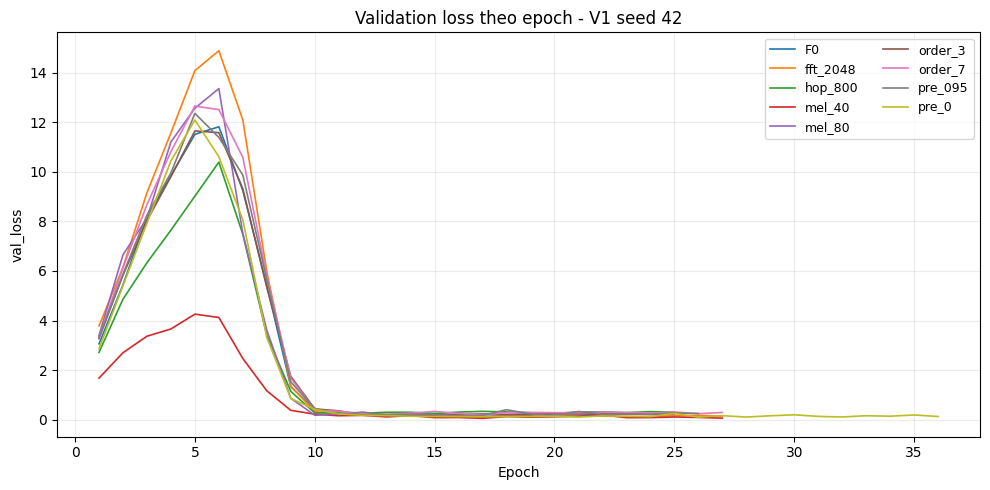

In [10]:
# B1.6 - Đọc history đầy đủ vào bộ nhớ cho B3, nhưng B1 CHỈ HIỂN THỊ 9 trial s42.
history_rows = []
history_series = {}
for tid,info in sorted(trial_info.items()):
    path = (ARTIFACTS_DIR / 'models' / tid / 'history.csv') if ARTIFACTS_DIR is not None else Path('__not_configured__') / tid / 'history.csv'
    hist = read_optional_csv(path)
    if hist.empty: continue
    if 'epoch' in hist:
        hist['epoch_no']=pd.to_numeric(hist['epoch'],errors='coerce')+1
    else:
        hist['epoch_no']=np.arange(1,len(hist)+1)
    history_series[tid]=hist
    vals = pd.to_numeric(hist.get('val_loss',pd.Series(dtype=float)),errors='coerce')
    history_rows.append({
        'trial_id':tid,'variant_id':info.get('variant_id'),
        'seed':info.get('seed'),'epochs_completed':len(hist),
        'best_epoch':info.get('best_epoch'),
        'best_val_loss':info.get('best_val_loss'),
        'last_val_loss':float(vals.iloc[-1]) if len(vals) else np.nan,
        'training_minutes':float(info.get('train_seconds',0))/60,
        'parameters':info.get('parameter_count')})
history_table_all=pd.DataFrame(history_rows)
history_table=(history_table_all[
    history_table_all['variant_id'].isin(B1_VARIANTS) &
    pd.to_numeric(history_table_all['seed'],errors='coerce').eq(B1_SEED)
].copy() if not history_table_all.empty else pd.DataFrame())
if history_table.empty:
    print('Chưa có history.csv - train bằng 03_Train.py rồi Run All.')
else:
    display(history_table.sort_values(['seed','variant_id']).round(4))
    fig,ax=plt.subplots(figsize=(10,5))
    for tid,hist in history_series.items():
        inf=trial_info[tid]
        if (int(inf.get('seed',-1)) != B1_SEED or inf.get('variant_id') not in B1_VARIANTS
                or 'val_loss' not in hist): continue
        ax.plot(hist['epoch_no'],pd.to_numeric(hist['val_loss'],errors='coerce'),
                label=inf.get('variant_id',tid),linewidth=1.2)
    if ax.lines:
        ax.set(title=f'Validation loss theo epoch - V1 seed {B1_SEED}',
               xlabel='Epoch',ylabel='val_loss')
        ax.legend(ncol=2,fontsize=9)
        ax.grid(alpha=.25)
        plt.tight_layout();plt.show()
    else:
        plt.close(fig)
        print('Không có val_loss history cho seed',B1_SEED)

Epoch hoàn thành: 47
Best val_loss epoch: 37 | val_loss: 0.005057 | val_acc: 1.0
Epoch đầu tiên val_accuracy = 100%: 28
Cuối training: val_loss= 0.008423 | val_accuracy= 1.0
training_metadata.best_epoch: 37


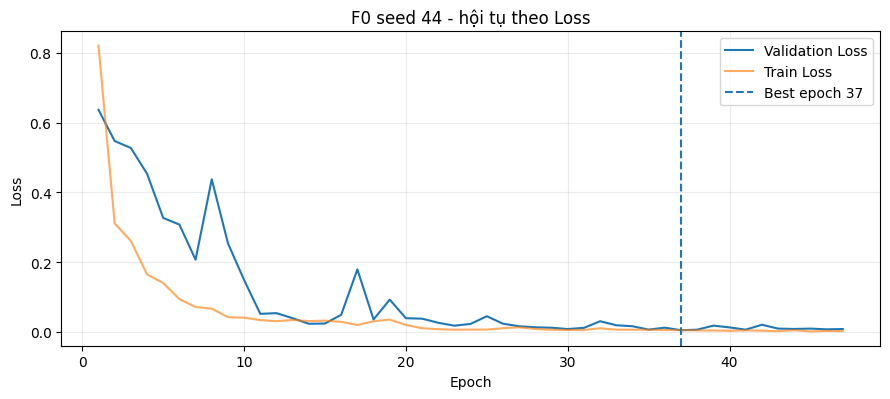

In [11]:
# B3.4 - Đọc history thực của F0 s44; nếu chưa có ở máy hiện tại thì báo thiếu.
tid = 'F0__V1__s44'
f0_44 = history_series.get(tid)
if f0_44 is None or f0_44.empty:
    print('Chưa tìm thấy history.csv cho F0 seed 44 ở thư mục model. '
          'Kiểm tra artifacts/models/F0__V1__s44/history.csv.')
else:
    h = f0_44.copy()
    for key in ('accuracy','loss','val_accuracy','val_loss','learning_rate'):
        if key in h: h[key] = pd.to_numeric(h[key],errors='coerce')
    best = h.loc[h['val_loss'].idxmin()]
    full = h.loc[h['val_accuracy'].ge(1-1e-8)]
    print('Epoch hoàn thành:',len(h))
    print('Best val_loss epoch:',int(best['epoch_no']), '| val_loss:',round(float(best['val_loss']),6),
          '| val_acc:',round(float(best['val_accuracy']),6))
    print('Epoch đầu tiên val_accuracy = 100%:',
          int(full['epoch_no'].iloc[0]) if not full.empty else 'không có')
    print('Cuối training: val_loss=',round(float(h['val_loss'].iloc[-1]),6),
          '| val_accuracy=',round(float(h['val_accuracy'].iloc[-1]),6))
    if tid in trial_info:
        declared = trial_info[tid].get('best_epoch')
        print('training_metadata.best_epoch:',declared)
        if declared is not None and int(declared)!=int(best['epoch_no']):
            print('CẢNH BÁO: best epoch history không trùng metadata - cần kiểm tra checkpoint!')
    fig, ax = plt.subplots(figsize=(9,4.1))
    ax.plot(h['epoch_no'],h['val_loss'],label='Validation Loss')
    ax.plot(h['epoch_no'],h['loss'],label='Train Loss',alpha=.65)
    ax.axvline(best['epoch_no'],linestyle='--',label=f'Best epoch {int(best["epoch_no"])}')
    ax.set(title='F0 seed 44 - hội tụ theo Loss',xlabel='Epoch',ylabel='Loss')
    ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.show()


In [12]:
print('B1: 9 OFAT x seed42 (khóa phạm vi, không combo/seed khác).')
print('B2:', 'ĐỦ so WAV seed42' if not b2_summary.empty else 'CHỜ 4 CSV seed42')
print('B3: 4 cấu hình x 3 seed =', len(b3_report), 'trial truy trực tiếp; metadata checkpoint:',
      'VERIFIED' if b3_provenance_ok else 'CHƯA NGHIỆM THU ĐẦY ĐỦ')
print('B3 paired:',len(b3_paired),'so sánh (3 candidate x 3 seed)')
display(b3_summary[['variant','n_seeds','accuracy_mean','accuracy_sd','macro_f1_mean',
                    'asthma_fn_sum','params']].round(5))
print('B3 kết luận trên Validation: chuyển sang C để kiểm tra combo, không sử dụng Test ở B.')


B1: 9 OFAT x seed42 (khóa phạm vi, không combo/seed khác).
B2: ĐỦ so WAV seed42
B3: 4 cấu hình x 3 seed = 12 trial truy trực tiếp; metadata checkpoint: VERIFIED
B3 paired: 9 so sánh (3 candidate x 3 seed)


,variant,n_seeds,accuracy_mean,accuracy_sd,macro_f1_mean,asthma_fn_sum,params
0,F0,3,0.97186,0.02928,0.96382,2,527994
1,pre_0,3,0.97186,0.01875,0.96333,2,527994
2,fft_2048,3,0.96970,0.00375,0.96035,2,527994
3,mel_40,3,0.96537,0.01352,0.95501,2,331386


B3 kết luận trên Validation: chuyển sang C để kiểm tra combo, không sử dụng Test ở B.


## Kết luận B — Từ F0 và OFAT sang các tổ hợp ở C

Khảo sát **9 cấu hình OFAT tại F0/V1/seed 42** cho thấy thay đổi riêng **pre-emphasis, số bộ lọc Mel và `n_fft`** có thể ảnh hưởng đến đặc trưng đầu vào và kết quả phân loại. B2 tiếp tục đối chiếu lỗi trên cùng WAV; B3 đánh giá **F0, Pre0, Mel40, FFT2048 qua ba seed 42–44**. Nhờ vậy, kết quả không chỉ dựa vào một giá trị Accuracy tại seed 42. Tuy nhiên, OFAT **không đo được đầy đủ tương tác** giữa các tham số.

**Giới hạn và bước tiếp theo:** B **chưa chọn C4 hoặc seed 44**. Kiến trúc V1 chỉ là biến được cố định để phân tích Front-End, theo cơ sở ở **A1.1**. Notebook **C** tiếp tục khảo sát **8 tổ hợp (`pre` × `Mel` × `FFT`) × 3 seed**; **C_Extend** kiểm chứng độ ổn định của việc bật/tắt pre-emphasis và bước đánh giá lại kiến trúc sau khi cố định C4. Chỉ kết hợp các kết quả này với lượng tử hóa và profiling ESP32-S3 mới đủ cơ sở lựa chọn nguyên mẫu. Không chọn cấu hình hoặc seed dựa trên Test Accuracy đỉnh.
